## KNN: ImageNet

Load default ResNet50 trained on ImageNet and predict prototypes for several classes.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import glob, os, pickle, cv2
from sklearn.metrics import label_ranking_average_precision_score as lrap
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import log_loss
from sklearn.metrics.pairwise import cosine_similarity
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.layers import GlobalAveragePooling2D

In [2]:
import tensorflow as tf
print(tf.__version__)

# Select GPU
print(tf.test.gpu_device_name())

gpus = tf.config.list_physical_devices('GPU')
print("Num GPUs available:", len(gpus))
try:
    tf.config.experimental.set_memory_growth(gpus[0], True) # don't allocate whole memory
except RuntimeError as e:
    print(e) # 'Invalid device or cannot modify virtual devices once initialized.'

2.8.1
/device:GPU:0
Num GPUs available: 1


2024-03-13 14:25:41.111436: I tensorflow/core/platform/cpu_feature_guard.cc:151] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 AVX512F FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-03-13 14:25:41.679156: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1525] Created device /device:GPU:0 with 47125 MB memory:  -> device: 0, name: Quadro RTX 8000, pci bus id: 0000:65:00.0, compute capability: 7.5


In [3]:
IMAGES_PATH   = '../data/Unsplash/images/'
CONCEPTS_PATH = '../data/Unsplash/prototypes/'
img_height = img_width = 224

### Load Test Images

In [4]:
classes = [c.split('/')[-1] for c in sorted(glob.glob(IMAGES_PATH + '*'))]
classes

['cheetah', 'snake', 'tiger', 'turtle', 'zebra']

In [5]:
test_set = tf.keras.utils.image_dataset_from_directory(
    IMAGES_PATH,
    shuffle=False,
    seed=123,
    image_size=(img_height, img_width),
    batch_size=None)

Found 212 files belonging to 5 classes.


2024-03-13 14:25:41.770604: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1525] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 47125 MB memory:  -> device: 0, name: Quadro RTX 8000, pci bus id: 0000:65:00.0, compute capability: 7.5


In [6]:
# Preprocess raw images (required by resnet initialized with imagenet weights)
test_set = test_set.map(lambda x, y: (tf.keras.applications.resnet50.preprocess_input(x), y))

In [7]:
# Get concept label vector from tf.Dataset
y_true_img = np.asarray([lab.numpy() for _, lab in test_set])

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


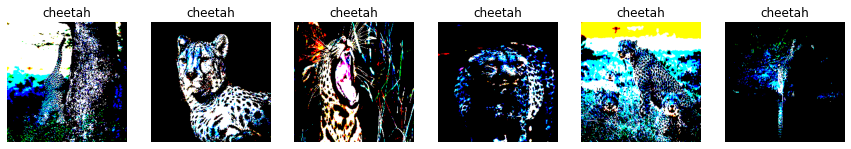

In [8]:
# Plot a few examples
plt.figure(figsize = (15, 10))
num_cols = 6
with tf.device('/CPU:0'):
    i=0
    for img, lab in test_set.take(num_cols):
        plt.subplot(1, num_cols, i + 1)
        plt.imshow(img)
        plt.title(classes[lab.numpy()])
        plt.axis("off")
        i+=1
plt.show()

### Load Prototype Images

In [9]:
concepts = [c.split('/')[-1] for c in sorted(glob.glob(CONCEPTS_PATH + '*'))]
concepts

['cheetah_proto', 'snake_proto', 'tiger_proto', 'turtle_proto', 'zebra_proto']

In [10]:
concept_set = tf.keras.utils.image_dataset_from_directory(
    CONCEPTS_PATH,
    shuffle=False,
    seed=123,
    image_size=(img_height, img_width),
    batch_size=None)

Found 150 files belonging to 5 classes.


In [11]:
# Preprocess raw images (required by resnet initialized with imagenet weights)
concept_set = concept_set.map(lambda x, y: (tf.keras.applications.resnet50.preprocess_input(x), y))

In [12]:
# Get concept label vector from tf.Dataset
y_true_con = np.asarray([lab.numpy() for _, lab in concept_set])

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


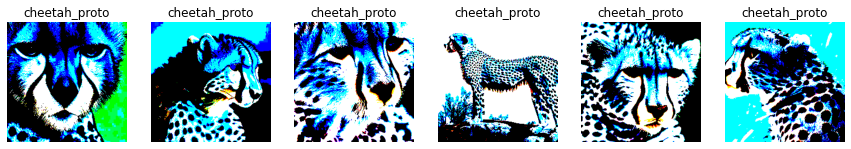

In [13]:
# Plot a few examples
plt.figure(figsize = (15, 10))
num_cols = 6
with tf.device('/CPU:0'):
    i=0
    for img, lab in concept_set.take(num_cols):
        plt.subplot(1, num_cols, i + 1)
        plt.imshow(img)
        plt.title(concepts[lab.numpy()])
        plt.axis("off")
        i+=1
plt.show()

### Load Random Images

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping i

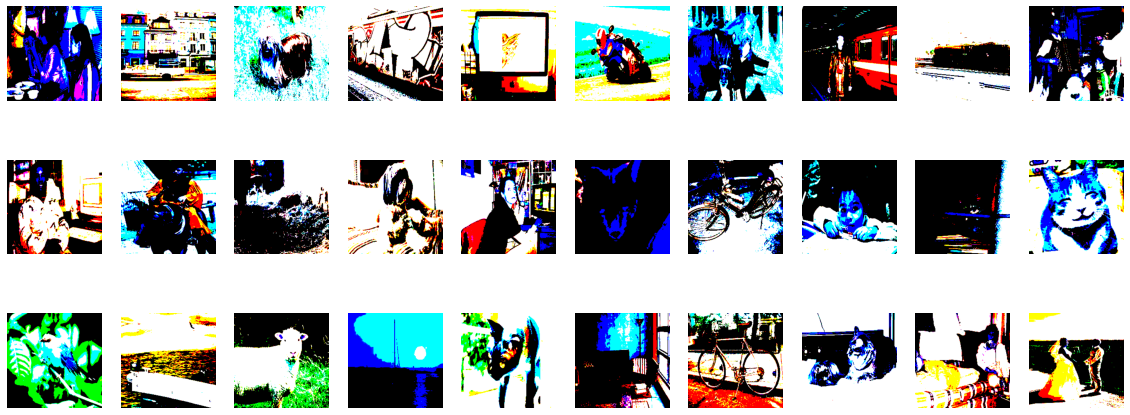

In [14]:
random_img_folder = '../data/broden1_224/images/pascal/'
input_size = img_height

random_imgs = os.listdir(random_img_folder)
random_imgs_filter = lambda f : all([rm not in f for rm in ['object', 'color', 'part']]) # only take 'natural' image

# Load same random images used for tcav fungi
with open('./beexplainable/metafiles/Fungi/raw/fungi_tcav_random.pickle', 'rb') as handle:
    files = pickle.load(handle)

random_dataset = [cv2.imread(random_img_folder+img)[...,::-1] for img in files]
random_dataset = [tf.image.resize(img, [img_width, img_height]) for img in random_dataset]
random_dataset = np.array([tf.keras.applications.resnet50.preprocess_input(img) for img in random_dataset])

plt.figure(figsize = (20, 8))
for i in range(30):
    plt.subplot(3, 10, i+1)
    plt.imshow(random_dataset[i])
    plt.axis('off')

### XAI: Predict Prototypes

In [15]:
# Load ResNet backbone
base_model = ResNet50(input_shape=(img_height, img_width, 3), weights='imagenet', include_top=False)

In [16]:
# Extract features of concept images with ResNet backbone
res_concepts = base_model.predict(concept_set.batch(32))
res_concepts = GlobalAveragePooling2D()(res_concepts)
tf.shape(res_concepts)

2024-03-13 14:25:50.513926: I tensorflow/stream_executor/cuda/cuda_dnn.cc:368] Loaded cuDNN version 8401
2024-03-13 14:25:51.000494: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2024-03-13 14:25:51.001181: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2024-03-13 14:25:51.001217: W tensorflow/stream_executor/gpu/asm_compiler.cc:80] Couldn't get ptxas version string: INTERNAL: Couldn't invoke ptxas --version
2024-03-13 14:25:51.002450: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2024-03-13 14:25:51.002541: W tensorflow/stream_executor/gpu/redzone_allocator.cc:314] INTERNAL: Failed to launch ptxas
Relying on driver to perform ptx compilation. 
Modify $PATH to customize ptxas location.
This message will be only logged once.


<tf.Tensor: shape=(2,), dtype=int32, numpy=array([ 150, 2048], dtype=int32)>

In [17]:
con_rand_set = []
for img, _ in concept_set.as_numpy_iterator():
    con_rand_set.append(img)
con_rand_set = np.asarray(con_rand_set)
con_rand_set = np.concatenate((con_rand_set, random_dataset))
con_rand_set.shape

y_true_con_rand = np.concatenate((y_true_con, np.array([len(concepts)]*len(random_dataset))))
y_true_con_rand.shape

(1150,)

In [18]:
con_rand_set.shape

(1150, 224, 224, 3)

In [19]:
res_con_rand = base_model.predict(con_rand_set)
res_con_rand = GlobalAveragePooling2D()(res_con_rand)
tf.shape(res_con_rand)

<tf.Tensor: shape=(2,), dtype=int32, numpy=array([1150, 2048], dtype=int32)>

In [20]:
# Extract features for all samples
test_activations = GlobalAveragePooling2D()(base_model.predict(test_set.batch(32)))
test_activations.shape

TensorShape([212, 2048])

#### Multiple random partitions, one kNN for all concepts

In [21]:
# One-hot-encode the concepts
concept_basis = OneHotEncoder().fit_transform([[0], [1], [2], [3], [4]]).toarray()
lookup_cls_concepts = [concept_basis[0], # cheetah
                       concept_basis[1], # snake
                       concept_basis[2], # tiger
                       concept_basis[3], # turtle
                       concept_basis[4]] # zebra

In [22]:
# Fit multiple kNNs for multiple random partitions of the random set
k = 8 # optimal k found in ResNet_Cluster_Concepts_Optim_k.ipynb
num_parts = 100 # how often to randomly select subsets of the random set
knn_probs = np.zeros((len(test_activations), len(concepts)+1)) # matrix of aggregated probs for every sample and every concept
for i in range(num_parts):
    # Select random indexes (starting after last concept img index)
    random_ids = np.random.choice( np.arange(len(y_true_con), len(con_rand_set)), 30,
                                   replace = False)

    # Overall index vector (concept indexes, then current random subset indexes)
    con_rand_ids = np.concatenate( (np.arange(len(y_true_con)), random_ids) )

    # Fit a kNN on current partition
    neigh = KNeighborsClassifier(n_neighbors=k)
    neigh.fit(res_con_rand.numpy()[con_rand_ids], y_true_con_rand[con_rand_ids])

    # Predict concepts for all test vectors
    knn_probs += neigh.predict_proba(test_activations)

# Average over number of random partitions
knn_probs /= num_parts
knn_probs

array([[0.86875, 0.     , 0.125  , 0.     , 0.     , 0.00625],
       [1.     , 0.     , 0.     , 0.     , 0.     , 0.     ],
       [0.125  , 0.     , 0.8725 , 0.     , 0.     , 0.0025 ],
       ...,
       [0.     , 0.     , 0.     , 0.     , 1.     , 0.     ],
       [0.     , 0.     , 0.     , 0.     , 1.     , 0.     ],
       [0.     , 0.     , 0.125  , 0.     , 0.875  , 0.     ]])

##### Offline metrics and mean scores per class

In [24]:
probs_cls_dict = {}
for c in classes:
    knn_probs_cls = knn_probs[np.where(y_true_img == classes.index(c)), :-1][0] # leave random component out
    probs_cls_dict[c] = np.mean(knn_probs_cls, axis=0)

    # Get true concept(s) based on true class
    true_con = lookup_cls_concepts[classes.index(c)]

    bce, cos_sim = [], []
    for p in knn_probs_cls:
        # Compute binary cross entropy
        bce.append( log_loss(true_con, p) )
        # Compute cosine sim.
        cos_sim.append( cosine_similarity(true_con.reshape(1, -1), p.reshape(1, -1))[0][0] )

    # Rank correlation
    rank = lrap(np.tile(true_con, (len(knn_probs_cls),1)), knn_probs_cls)

    print(c)
    print('BCE:')
    print(str(np.round(np.mean(bce),4)) + '+/-' + str(np.round(np.std(bce),4)))
    print('Cosine Similarity:')
    print(str(np.round(np.mean(cos_sim),4)) + '+/-' + str(np.round(np.std(cos_sim),4)))
    print('Rank Correlation:')
    print(rank)
    print()

cheetah
BCE:
0.0874+/-0.1832
Cosine Similarity:
0.9177+/-0.2126
Rank Correlation:
0.9444444444444445

snake
BCE:
0.0107+/-0.0326
Cosine Similarity:
0.9956+/-0.022
Rank Correlation:
1.0

tiger
BCE:
0.2046+/-1.1918
Cosine Similarity:
0.9715+/-0.1509
Rank Correlation:
0.9813953488372094

turtle
BCE:
0.0496+/-0.1031
Cosine Similarity:
0.9589+/-0.103
Rank Correlation:
0.9642857142857143

zebra
BCE:
0.0915+/-0.0972
Cosine Similarity:
0.9364+/-0.1022
Rank Correlation:
0.9583333333333334



In [24]:
probs_cls_dict

{'cheetah': array([0.85571429, 0.01154762, 0.0947619 , 0.        , 0.01785714]),
 'snake': array([0.00331081, 0.97192568, 0.        , 0.01652027, 0.        ]),
 'tiger': array([0.05392442, 0.00273256, 0.92531977, 0.        , 0.        ]),
 'turtle': array([0.00369048, 0.03276786, 0.03568452, 0.89089286, 0.        ]),
 'zebra': array([0.01291667, 0.        , 0.17005208, 0.        , 0.81510417])}

In [25]:
probs_con_dict = {}
for c in concepts:
    probs_con_dict[c] = np.zeros(len(classes))
    for i in range(len(classes)):
        probs_con_dict[c][i] = probs_cls_dict[classes[i]][concepts.index(c)]
probs_con_dict

{'cheetah_proto': array([0.85571429, 0.00331081, 0.05392442, 0.00369048, 0.01291667]),
 'snake_proto': array([0.01154762, 0.97192568, 0.00273256, 0.03276786, 0.        ]),
 'tiger_proto': array([0.0947619 , 0.        , 0.92531977, 0.03568452, 0.17005208]),
 'turtle_proto': array([0.        , 0.01652027, 0.        , 0.89089286, 0.        ]),
 'zebra_proto': array([0.01785714, 0.        , 0.        , 0.        , 0.81510417])}

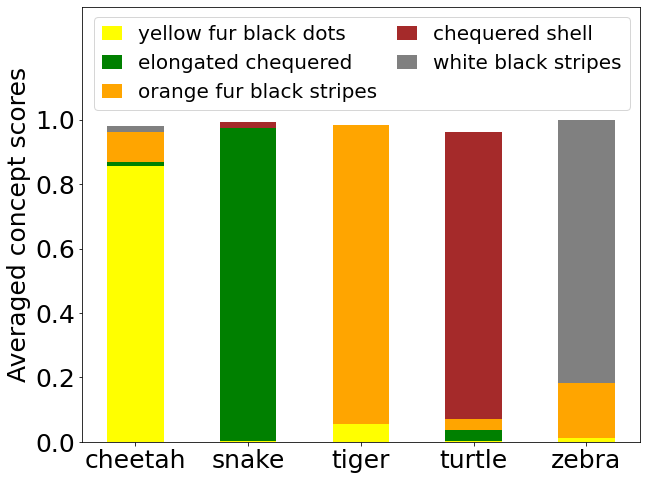

In [26]:
concept_prompts = ['yellow fur black dots', 'elongated chequered', 'orange fur black stripes', 'chequered shell', 'white black stripes']
con_colors = ['yellow', 'green', 'orange', 'brown', 'grey']
fontsize = 25
plt.figure(figsize=(10,8))
bottom = np.zeros(len(classes))
for i, (con, probs) in enumerate(probs_con_dict.items()):
    plt.bar(classes, probs, width=0.5, label=con, bottom=bottom, color=con_colors[i])
    bottom += probs

plt.ylim(0.0, 1.35)
plt.legend(concept_prompts, loc='upper right', fontsize=fontsize-5,
           ncol=2, bbox_to_anchor=(1, 1), handlelength=1.0, columnspacing=1.0)
plt.ylabel('Averaged concept scores', fontsize=fontsize)
plt.xticks(fontsize=fontsize); plt.yticks(np.linspace(0.0, 1.0, 6), fontsize=fontsize)
plt.savefig('./beexplainable/figures/knn_vs_tcav_vs_ibd/mean_imagenet_knn_stacked.png', bbox_inches='tight')
plt.show()

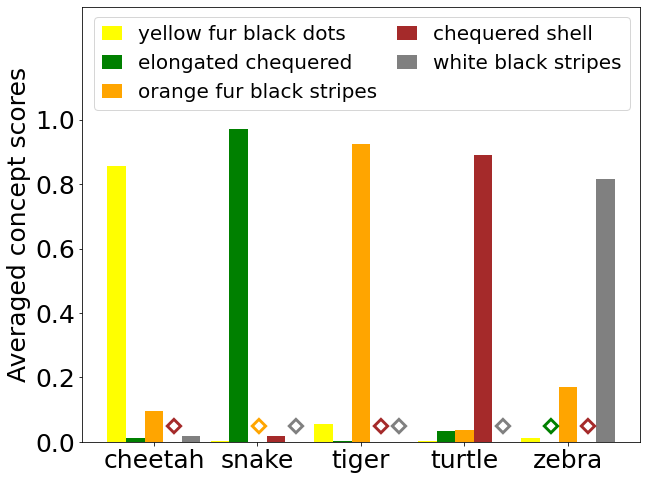

In [27]:
x = np.arange(len(classes))  # the label locations
width = 0.18  # the width of the bars
multiplier = -1
fontsize = 25
con_colors = ['yellow', 'green', 'orange', 'brown', 'grey']

fig, ax = plt.subplots(figsize=(10, 8))  # Create axes for text placement
for i, (con, freq) in enumerate(probs_con_dict.items()):
   offset = width * multiplier
   rects = plt.bar(x + offset, freq, width, label=con, color=con_colors[i])
   multiplier += 1

   # Add asterisks for zero-height bars
   for rect, height in zip(rects, freq):
       if height < 1e-3:
           ax.text(rect.get_x() + rect.get_width() / 2,
                   height,  # Adjust vertical position slightly
                   '$\diamond$', ha='center', va='bottom', fontsize=fontsize+10, color=con_colors[i])

plt.xticks(x + width, classes, fontsize=fontsize)
plt.yticks(np.linspace(0.0, 1.0, 6), fontsize=fontsize)
plt.ylim(0.0, 1.35)
plt.ylabel('Averaged concept scores', fontsize=fontsize)
plt.legend(concept_prompts, loc='upper right', fontsize=fontsize-5,
           ncol=2, bbox_to_anchor=(1, 1), handlelength=1.0, columnspacing=1.0)
plt.savefig('./beexplainable/figures/knn_vs_tcav_vs_ibd/mean_imagenet_knn.png', bbox_inches='tight')
plt.show()

##### Frequency of dominant prototypes

In [45]:
# Count how often each concept is predicted as dominant concept (knn_prob == max_prob)
sig_cls_dict = {}
for c in classes:
    cls_ind = np.where(y_true_img == classes.index(c))
    sig_cls_dict[c] = np.count_nonzero(knn_probs[cls_ind, :len(concepts)][0] ==
                                       np.tile(np.max(knn_probs[cls_ind, :len(concepts)][0], axis=1),
                                               (len(concepts),1)).T,
                                                axis=0) / len(cls_ind[0])
sig_cls_dict

{'cheetah': array([0.95238095, 0.07142857, 0.14285714, 0.07142857, 0.11904762]),
 'snake': array([0., 1., 0., 0., 0.]),
 'tiger': array([0.04651163, 0.02325581, 0.97674419, 0.02325581, 0.02325581]),
 'turtle': array([0.04761905, 0.07142857, 0.04761905, 0.97619048, 0.04761905]),
 'zebra': array([0.        , 0.        , 0.08333333, 0.        , 1.        ])}

In [46]:
# Invert dictionary (for plotting purposes)
sig_con_dict = {}
for c in concepts:
    sig_con_dict[c] = np.zeros(len(classes))
    for i in range(len(classes)):
        sig_con_dict[c][i] = sig_cls_dict[classes[i]][concepts.index(c)]
sig_con_dict

{'cheetah_proto': array([0.95238095, 0.        , 0.04651163, 0.04761905, 0.        ]),
 'snake_proto': array([0.07142857, 1.        , 0.02325581, 0.07142857, 0.        ]),
 'tiger_proto': array([0.14285714, 0.        , 0.97674419, 0.04761905, 0.08333333]),
 'turtle_proto': array([0.07142857, 0.        , 0.02325581, 0.97619048, 0.        ]),
 'zebra_proto': array([0.11904762, 0.        , 0.02325581, 0.04761905, 1.        ])}

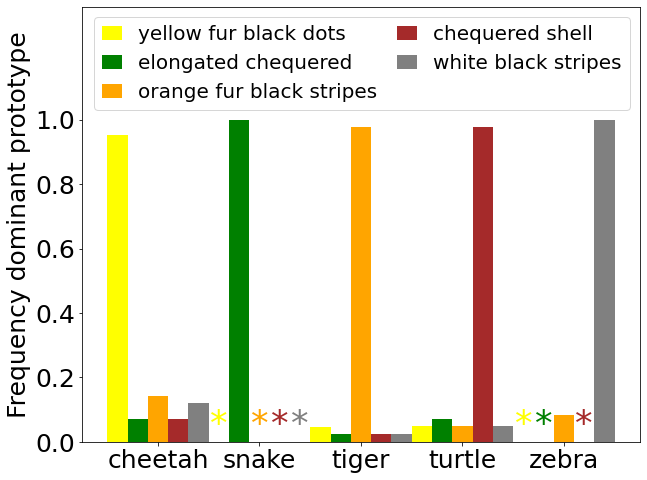

In [48]:
x = np.arange(len(classes))  # the label locations
width = 0.2  # the width of the bars
multiplier = -1
fontsize = 25
con_colors = ['yellow', 'green', 'orange', 'brown', 'grey']

fig, ax = plt.subplots(figsize=(10, 8))  # Create axes for text placement
for i, (con, freq) in enumerate(sig_con_dict.items()):
   offset = width * multiplier
   rects = plt.bar(x + offset, freq, width, label=con, color=con_colors[i])
   multiplier += 1

   # Add asterisks for zero-height bars
   for rect, height in zip(rects, freq):
       if height == 0:
           ax.text(rect.get_x() + rect.get_width() / 2,
                   height,  # Adjust vertical position slightly
                   '*', ha='center', va='bottom', fontsize=fontsize+10, color=con_colors[i])

plt.xticks(x + width, classes, fontsize=fontsize)
plt.yticks(np.linspace(0.0, 1.0, 6), fontsize=fontsize)
plt.ylim(0.0, 1.35)
plt.ylabel('Frequency dominant prototype', fontsize=fontsize)
plt.legend(concept_prompts, loc='upper right', fontsize=fontsize-5,
           ncol=2, bbox_to_anchor=(1, 1), handlelength=1.0, columnspacing=1.0)
plt.savefig('./beexplainable/figures/knn_vs_tcav_vs_ibd/imagenet_knn_freq.png', bbox_inches='tight')
plt.show()

#### Multiple random partitions, one kNN per concept

In [21]:
# One-hot-encode the concepts
concept_basis = OneHotEncoder().fit_transform([[0], [1], [2], [3], [4]]).toarray()
lookup_cls_concepts = [concept_basis[0], # cheetah
                       concept_basis[1], # snake
                       concept_basis[2], # tiger
                       concept_basis[3], # turtle
                       concept_basis[4]] # zebra

In [24]:
# Fit multiple kNNs for multiple random partitions of thre random set
k = 22 # optimal k found in ResNet_Cluster_Concepts_Optim_k.ipynb
num_parts = 100 # how often to randomly select subsets of the random set
knn_probs = np.zeros((len(test_activations), len(concepts))) # matrix of aggregated probs for every sample and every concept
for i in range(num_parts):

    # Select random indexes (starting after last concept img index)
    random_ids = np.random.choice( np.arange(len(y_true_con), len(con_rand_set)), 30,
                                   replace = False)

    # Fit a kNN on current partition for every concept
    for j in range(len(concepts)):
        # Overall index vector (concept indexes, then current random subset indexes)
        con_ids = np.where(np.asarray(y_true_con) == j)[0]
        con_rand_ids = np.concatenate( (con_ids, random_ids) )

        neigh = KNeighborsClassifier(n_neighbors=k)
        neigh.fit(res_con_rand.numpy()[con_rand_ids], y_true_con_rand[con_rand_ids])

        # Predict concepts for all test vectors
        knn_probs[:, j] += neigh.predict_proba(test_activations)[:, 0] # 2nd prob. is for random

# Average over number of random partitions
knn_probs /= num_parts
knn_probs

array([[0.99681818, 0.61136364, 0.78681818, 0.59909091, 0.68681818],
       [0.99636364, 0.52318182, 0.79909091, 0.55818182, 0.50727273],
       [0.92681818, 0.53636364, 0.89454545, 0.50318182, 0.68590909],
       ...,
       [0.92136364, 0.66863636, 0.97590909, 0.70090909, 1.        ],
       [0.88181818, 0.50272727, 0.97727273, 0.75409091, 1.        ],
       [0.86727273, 0.57681818, 0.87318182, 0.66727273, 0.99136364]])

##### Offline metrics and mean scores per class

In [23]:
probs_cls_dict = {}
for c in classes:
    knn_probs_cls = knn_probs[np.where(y_true_img == classes.index(c))]
    probs_cls_dict[c] = np.mean(knn_probs_cls, axis=0)

    # Get true concept(s) based on true class
    true_con = lookup_cls_concepts[classes.index(c)]

    bce, cos_sim = 0.0, 0.0
    for p in knn_probs_cls:
        # Compute binary cross entropy
        bce += log_loss(true_con, p)
        # Compute cosine sim.
        cos_sim += cosine_similarity(true_con.reshape(1, -1), p.reshape(1, -1))[0][0]

    print(c)
    print('BCE:')
    print(bce/len(knn_probs_cls));
    print('Cosine Similarity:')
    print(cos_sim/len(knn_probs_cls))
    print()

cheetah
BCE:
0.7698230056213697
Cosine Similarity:
0.6218402612127977

snake
BCE:
0.7506523078406461
Cosine Similarity:
0.6194024770475833

tiger
BCE:
1.0550003254908438
Cosine Similarity:
0.5685982709384572

turtle
BCE:
0.6075933418791558
Cosine Similarity:
0.6749943913797906

zebra
BCE:
1.968135467275121
Cosine Similarity:
0.538563180346508



In [24]:
probs_cls_dict

{'cheetah': array([0.95335498, 0.53844156, 0.70472944, 0.54160173, 0.56905844]),
 'snake': array([0.62750614, 0.92640049, 0.56132678, 0.69361179, 0.4164742 ]),
 'tiger': array([0.85471459, 0.48918605, 0.92526427, 0.59264271, 0.66303383]),
 'turtle': array([0.53035714, 0.57819264, 0.51165584, 0.92737013, 0.36672078]),
 'zebra': array([0.84142992, 0.55027462, 0.87754735, 0.69089962, 0.96047348])}

In [28]:
probs_con_dict = {}
for c in concepts:
    probs_con_dict[c] = np.zeros(len(classes))
    for i in range(len(classes)):
        probs_con_dict[c][i] = probs_cls_dict[classes[i]][concepts.index(c)]/len(concepts)
probs_con_dict

{'cheetah_proto': array([0.190671  , 0.12550123, 0.17094292, 0.10607143, 0.16828598]),
 'snake_proto': array([0.10768831, 0.1852801 , 0.09783721, 0.11563853, 0.11005492]),
 'tiger_proto': array([0.14094589, 0.11226536, 0.18505285, 0.10233117, 0.17550947]),
 'turtle_proto': array([0.10832035, 0.13872236, 0.11852854, 0.18547403, 0.13817992]),
 'zebra_proto': array([0.11381169, 0.08329484, 0.13260677, 0.07334416, 0.1920947 ])}

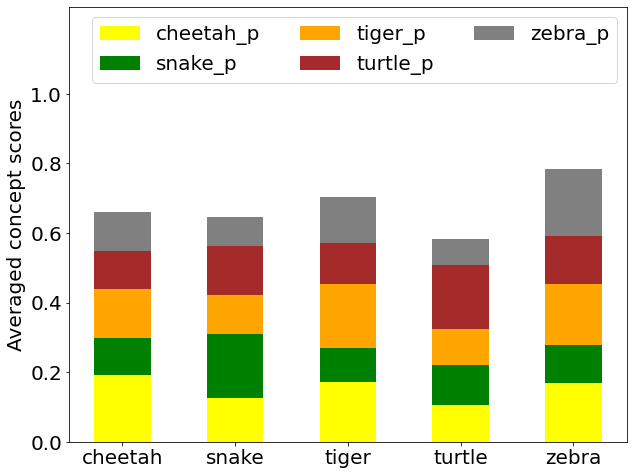

In [29]:
con_colors = ['yellow', 'green', 'orange', 'brown', 'grey']
fontsize = 20
plt.figure(figsize=(10,8))
bottom = np.zeros(len(classes))
for i, (con, probs) in enumerate(probs_con_dict.items()):
    plt.bar(classes, probs, width=0.5, label=con, bottom=bottom, color=con_colors[i])
    bottom += probs

plt.ylim(0.0, 1.25)
plt.legend([c[:-4] for c in concepts], loc='upper right',
           fontsize=fontsize, ncol=3, bbox_to_anchor=(1, 1))
plt.ylabel('Averaged concept scores', fontsize=fontsize)
plt.xticks(fontsize=fontsize); plt.yticks(np.linspace(0.0, 1.0, 6), fontsize=fontsize)
#plt.savefig('./beexplainable/figures/knn_vs_tcav/mean_imagenet_knn_multilabel.png', bbox_inches='tight')
plt.show()

In [30]:
probs_con_dict = {}
for c in concepts:
    probs_con_dict[c] = np.zeros(len(classes))
    for i in range(len(classes)):
        probs_con_dict[c][i] = probs_cls_dict[classes[i]][concepts.index(c)]
probs_con_dict

{'cheetah_proto': array([0.95335498, 0.62750614, 0.85471459, 0.53035714, 0.84142992]),
 'snake_proto': array([0.53844156, 0.92640049, 0.48918605, 0.57819264, 0.55027462]),
 'tiger_proto': array([0.70472944, 0.56132678, 0.92526427, 0.51165584, 0.87754735]),
 'turtle_proto': array([0.54160173, 0.69361179, 0.59264271, 0.92737013, 0.69089962]),
 'zebra_proto': array([0.56905844, 0.4164742 , 0.66303383, 0.36672078, 0.96047348])}

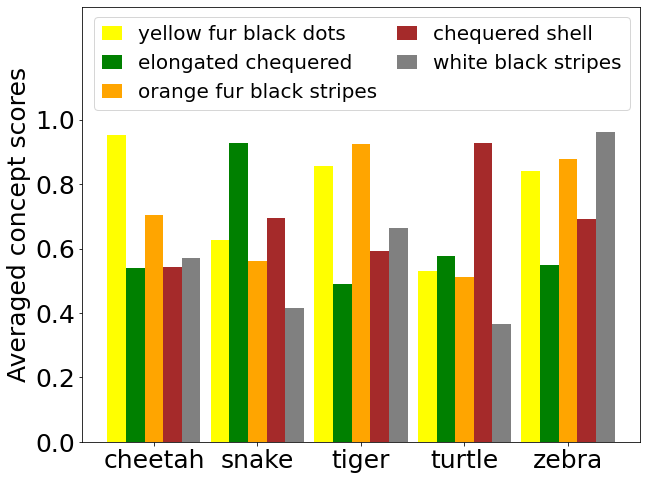

In [32]:
concept_prompts = ['yellow fur black dots', 'elongated chequered', 'orange fur black stripes', 'chequered shell', 'white black stripes']
x = np.arange(len(classes))  # the label locations
width = 0.18  # the width of the bars
multiplier = -1
fontsize = 25
con_colors = ['yellow', 'green', 'orange', 'brown', 'grey']

fig, ax = plt.subplots(figsize=(10, 8))  # Create axes for text placement
for i, (con, freq) in enumerate(probs_con_dict.items()):
   offset = width * multiplier
   rects = plt.bar(x + offset, freq, width, label=con, color=con_colors[i])
   multiplier += 1

   # Add asterisks for zero-height bars
   for rect, height in zip(rects, freq):
       if height < 1e-3:
           ax.text(rect.get_x() + rect.get_width() / 2,
                   height,  # Adjust vertical position slightly
                   '$\diamond$', ha='center', va='bottom', fontsize=fontsize+10, color=con_colors[i])

plt.xticks(x + width, classes, fontsize=fontsize)
plt.yticks(np.linspace(0.0, 1.0, 6), fontsize=fontsize)
plt.ylim(0.0, 1.35)
plt.ylabel('Averaged concept scores', fontsize=fontsize)
plt.legend(concept_prompts, loc='upper right', fontsize=fontsize-5,
           ncol=2, bbox_to_anchor=(1, 1), handlelength=1.0, columnspacing=1.0)
#plt.savefig('./beexplainable/figures/knn_vs_tcav_vs_ibd/mean_imagenet_knn.png', bbox_inches='tight')
plt.show()

##### Frequency of dominant prototypes

In [38]:
# Count how often each concept is predicted as dominant concept (knn_prob == max_prob)
sig_cls_dict = {}
for c in classes:
    cls_ind = np.where(y_true_img == classes.index(c))
    sig_cls_dict[c] = np.count_nonzero(knn_probs[cls_ind, :len(concepts)][0] ==
                                       np.tile(np.max(knn_probs[cls_ind, :len(concepts)][0], axis=1),
                                               (len(concepts),1)).T,
                                                axis=0) / len(cls_ind[0])
sig_cls_dict

{'cheetah': array([0.95238095, 0.07142857, 0.16666667, 0.07142857, 0.07142857]),
 'snake': array([0., 1., 0., 0., 0.]),
 'tiger': array([0.04651163, 0.02325581, 0.97674419, 0.02325581, 0.04651163]),
 'turtle': array([0.04761905, 0.11904762, 0.04761905, 0.97619048, 0.04761905]),
 'zebra': array([0.125 , 0.    , 0.9375, 0.    , 1.    ])}

In [39]:
# Invert dictionary (for plotting purposes)
sig_con_dict = {}
for c in concepts:
    sig_con_dict[c] = np.zeros(len(classes))
    for i in range(len(classes)):
        sig_con_dict[c][i] = sig_cls_dict[classes[i]][concepts.index(c)]
sig_con_dict

{'cheetah_proto': array([0.95238095, 0.        , 0.04651163, 0.04761905, 0.125     ]),
 'snake_proto': array([0.07142857, 1.        , 0.02325581, 0.11904762, 0.        ]),
 'tiger_proto': array([0.16666667, 0.        , 0.97674419, 0.04761905, 0.9375    ]),
 'turtle_proto': array([0.07142857, 0.        , 0.02325581, 0.97619048, 0.        ]),
 'zebra_proto': array([0.07142857, 0.        , 0.04651163, 0.04761905, 1.        ])}

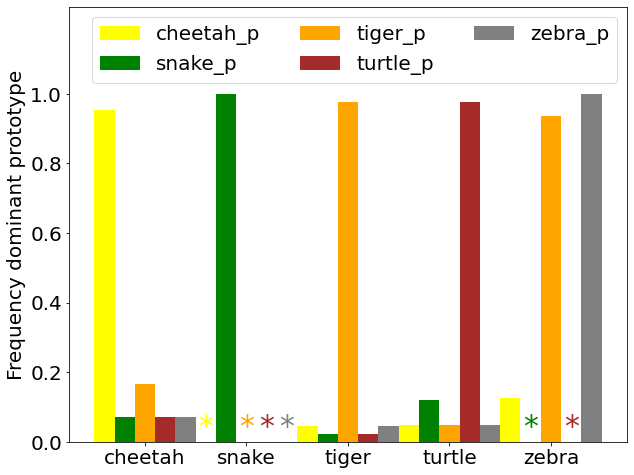

In [40]:
x = np.arange(len(classes))  # the label locations
width = 0.2  # the width of the bars
multiplier = -1
fontsize = 20
con_colors = con_colors = ['yellow', 'green', 'orange', 'brown', 'grey']

fig, ax = plt.subplots(figsize=(10, 8))  # Create axes for text placement
for i, (con, freq) in enumerate(sig_con_dict.items()):
   offset = width * multiplier
   rects = plt.bar(x + offset, freq, width, label=con, color=con_colors[i])
   multiplier += 1

   # Add asterisks for zero-height bars
   for rect, height in zip(rects, freq):
       if height == 0:
           ax.text(rect.get_x() + rect.get_width() / 2,
                   height,  # Adjust vertical position slightly
                   '*', ha='center', va='bottom', fontsize=fontsize+10, color=con_colors[i])

plt.xticks(x + width, classes, fontsize=fontsize)
plt.yticks(np.linspace(0.0, 1.0, 6), fontsize=fontsize)
plt.ylim(0.0, 1.25)
plt.ylabel('Frequency dominant prototype', fontsize=fontsize)
plt.legend([c[:-4] for c in concepts], loc='upper right',
           fontsize=fontsize, ncol=3, bbox_to_anchor=(1, 1))
plt.savefig('./beexplainable/figures/knn_vs_tcav/imagenet_knn_freq_multilabel.png', bbox_inches='tight')
plt.show()

#### Bonus: Stats for other thresholds

In [51]:
# Count how often each concept is predicted as dominant concept (knn_prob == max_prob)
sig_cls_dict = {}
thresh = 0.8
for c in classes:
    cls_ind = np.where(y_true_img == classes.index(c))
    sig_cls_dict[c] = np.count_nonzero(knn_probs[cls_ind, :len(concepts)][0] >=thresh,
                                                axis=0) / len(cls_ind[0])
sig_cls_dict

{'cheetah': array([0.76190476, 0.        , 0.        , 0.        , 0.        ]),
 'snake': array([0.        , 0.81081081, 0.        , 0.        , 0.        ]),
 'tiger': array([0.02325581, 0.        , 0.86046512, 0.        , 0.        ]),
 'turtle': array([0.        , 0.        , 0.        , 0.66666667, 0.        ]),
 'zebra': array([0.        , 0.        , 0.        , 0.        , 0.77083333])}

In [52]:
sig_con_dict = {}
for c in concepts:
    sig_con_dict[c] = np.zeros(len(classes))
    for i in range(len(classes)):
        sig_con_dict[c][i] = sig_cls_dict[classes[i]][concepts.index(c)]
sig_con_dict

{'cheetah_proto': array([0.76190476, 0.        , 0.02325581, 0.        , 0.        ]),
 'snake_proto': array([0.        , 0.81081081, 0.        , 0.        , 0.        ]),
 'tiger_proto': array([0.        , 0.        , 0.86046512, 0.        , 0.        ]),
 'turtle_proto': array([0.        , 0.        , 0.        , 0.66666667, 0.        ]),
 'zebra_proto': array([0.        , 0.        , 0.        , 0.        , 0.77083333])}

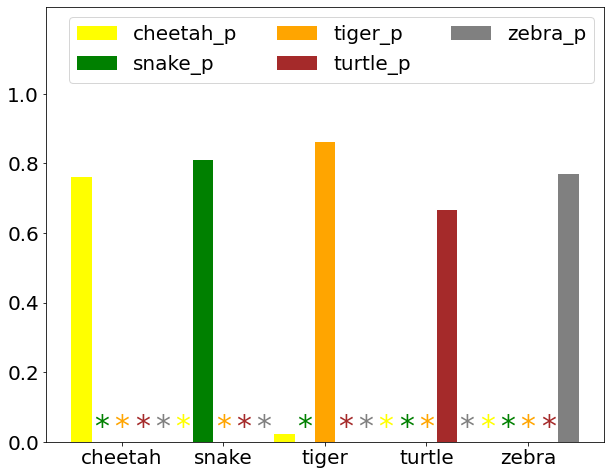

In [54]:
x = np.arange(len(classes))  # the label locations
width = 0.2  # the width of the bars
multiplier = -1
fontsize = 20
con_colors = con_colors = ['yellow', 'green', 'orange', 'brown', 'grey']

fig, ax = plt.subplots(figsize=(10, 8))  # Create axes for text placement
for i, (con, freq) in enumerate(sig_con_dict.items()):
   offset = width * multiplier
   rects = plt.bar(x + offset, freq, width, label=con, color=con_colors[i])
   multiplier += 1

   # Add asterisks for zero-height bars
   for rect, height in zip(rects, freq):
       if height == 0:
           ax.text(rect.get_x() + rect.get_width() / 2,
                   height,  # Adjust vertical position slightly
                   '*', ha='center', va='bottom', fontsize=fontsize+10, color=con_colors[i])

plt.xticks(x + width, classes, fontsize=fontsize)
plt.yticks(np.linspace(0.0, 1.0, 6), fontsize=fontsize)
plt.ylim(0.0, 1.25)
plt.legend([c[:-4] for c in concepts], loc='upper right',
           fontsize=fontsize, ncol=3, bbox_to_anchor=(1, 1))
plt.savefig('./beexplainable/figures/knn_vs_tcav/imagenet_knn_freq_08.png', bbox_inches='tight')
plt.show()